# Reproduce the Final Report

This notebook runs the complete allocation and analysis pipeline from the packaged inputs, then checks the resulting tables against the supplied final-report reference. Install the pinned environment first. BibTeX and `IEEEtran.bst` must be available; the optional final PDF cell additionally requires `pdflatex`.

Outputs are written to `results/reproduced/`. Runtime depends on hardware and solver branches; allow several minutes or longer for the selection reruns and the 49 additional allocation settings. The supplied reference results remain unchanged.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys
import time
import pandas as pd
from IPython.display import display, Image
from lowrisk_portfolio.paths import ROOT

output = ROOT / "results/reproduced"
output.mkdir(parents=True, exist_ok=True)
print("Python:", sys.version.split()[0])

Python: 3.13.2


## Verify every input, including the original supplementary archive

In [2]:
_ = subprocess.run([sys.executable, str(ROOT / "scripts/verify_data.py")], cwd=ROOT, check=True)

Verified 12 input files.


## Execute the complete pipeline

The saved log contains all stage output and numerical warnings. A failed stage stops execution and displays the end of the log.

In [3]:
started = time.perf_counter()
log_path = output / "execution.log"
with log_path.open("w") as log:
    result = subprocess.run([sys.executable, "-m", "lowrisk_portfolio.cli"], cwd=ROOT, stdout=log, stderr=subprocess.STDOUT)
if result.returncode:
    print("\n".join(log_path.read_text().splitlines()[-30:]))
    result.check_returncode()
manifest = json.loads((output / "pipeline_manifest.json").read_text())
assert manifest["status"] == "complete"
display(pd.DataFrame(manifest["stages"])[["name", "seconds"]])
print(f"Complete in {time.perf_counter() - started:.1f} seconds. Log: results/reproduced/execution.log")

,name,seconds
0,experiment,56.026
1,mechanisms,18.258
2,selection_comparison,5.364
3,market_inference,0.846
4,ext09_alpha_bab,0.632
5,extE_factor_cov,34.905
6,selection_revisions,35.540
7,allocation_sensitivity,98.932
8,report,2.117
9,verify_benchmarks,0.745


Complete in 253.4 seconds. Log: results/reproduced/execution.log


## Compare against the supplied results

In [4]:
subprocess.run([sys.executable, str(ROOT / "scripts/compare_reference.py"), "--output", str(output)], cwd=ROOT, check=True)
comparison = json.loads((output / "reference_comparison.json").read_text())
assert comparison["status"] == "passed"
display(pd.DataFrame(comparison["tables"]))

All 35 reference tables agree within atol=1e-08, rtol=1e-07.
All 12 numbered manuscript tables match the committed report.


,table,rows,maximum_absolute_difference
0,data_audit.csv,6450,0.000000e+00
1,monthly_returns.csv,24510,0.000000e+00
2,holdings.csv.gz,122550,0.000000e+00
3,model_metrics.csv,570,0.000000e+00
4,paired_comparisons.csv,1080,0.000000e+00
5,benchmark_returns.csv,215,0.000000e+00
6,benchmark_metrics.csv,15,0.000000e+00
7,regime_metrics.csv,1053,0.000000e+00
8,sharpe_bootstrap.csv,36,0.000000e+00
9,mechanism_summary.csv,19,0.000000e+00


## Inspect the regenerated performance and figure

,model,cagr,annual_volatility,sharpe,max_drawdown
0,gmvp_lw_identity,0.134819,0.108216,1.114476,-0.311617
1,source_weight,0.140473,0.113922,1.110432,-0.290038
2,mix_1n,0.134590,0.109361,1.102128,-0.315501
3,gmvp_ridge,0.133541,0.108792,1.098390,-0.318762
4,gmvp_sample,0.133567,0.109058,1.096050,-0.325841
5,norm_gmvp,0.133567,0.109058,1.096050,-0.325841
6,equal_weight,0.135241,0.111766,1.086542,-0.307689
7,inverse_vol,0.134415,0.111123,1.085617,-0.308003
8,gmvp_qis,0.131848,0.108730,1.085470,-0.310562
9,vol_timing,0.133681,0.110799,1.082606,-0.306427


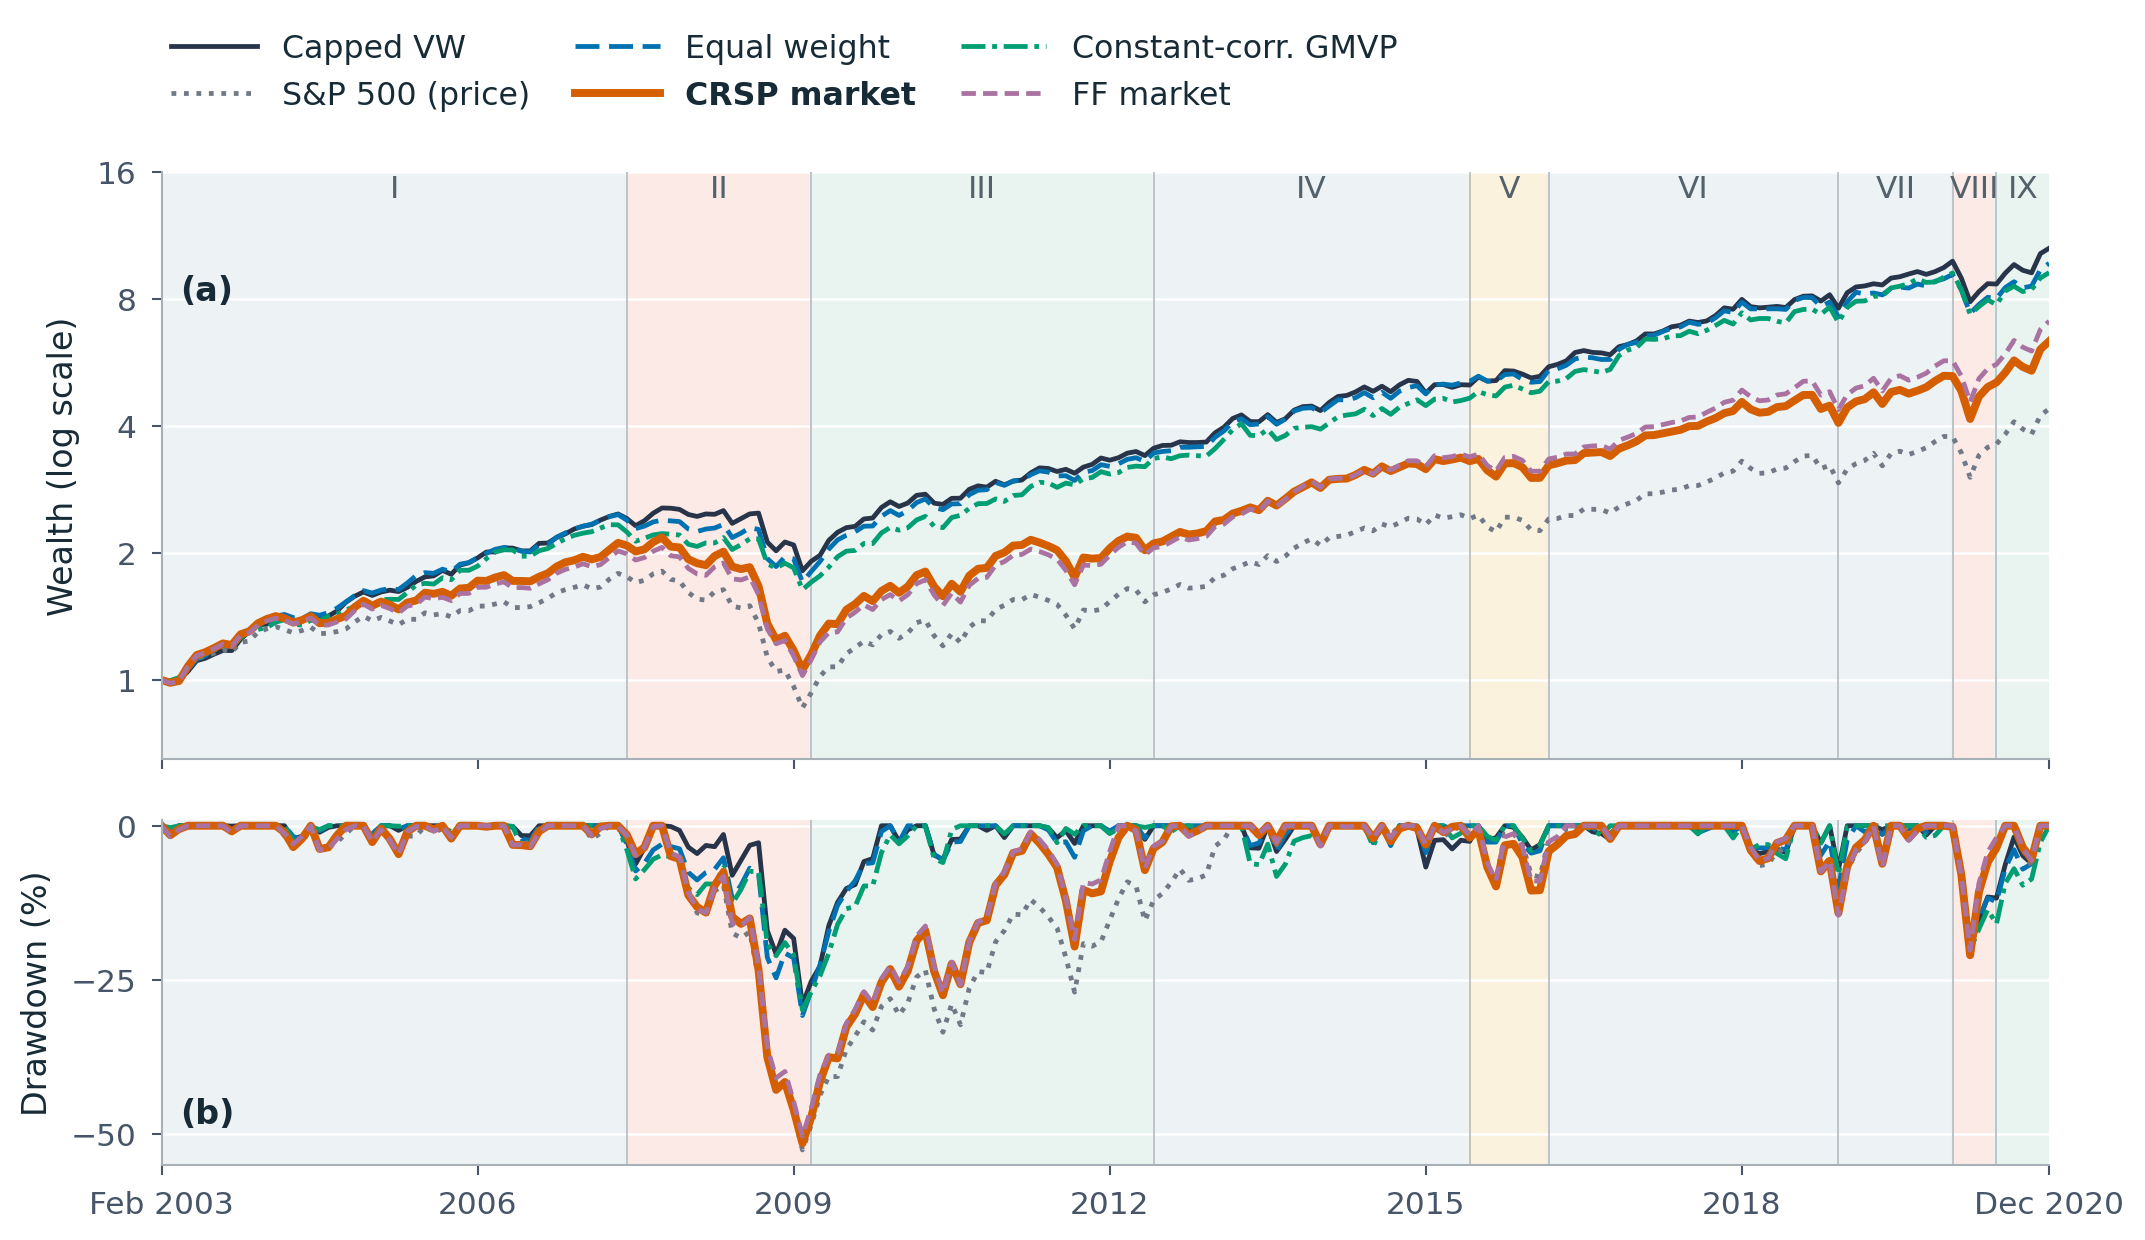

Regenerated report source: results/reproduced/paper/main.tex


In [5]:
metrics = pd.read_csv(output / "model_metrics.csv")
main = metrics.query("scenario == 'total_observed_drift10' and period == 'full'")
display(main[["model", "cagr", "annual_volatility", "sharpe", "max_drawdown"]].sort_values("sharpe", ascending=False).reset_index(drop=True))
display(Image(filename=str(output / "figures/wealth_drawdown.png")))
assert (output / "paper/main.tex").is_file()
print("Regenerated report source: results/reproduced/paper/main.tex")

## Optional PDF compilation

The report source includes the figures and bibliography. Set `COMPILE_PDF = True` to compile it locally. The supplied reference PDF is available at `paper/report.pdf` regardless of TeX availability.

In [6]:
COMPILE_PDF = False
if COMPILE_PDF:
    for _ in range(2):
        result = subprocess.run(["pdflatex", "-interaction=nonstopmode", "-halt-on-error", "main.tex"], cwd=output / "paper", capture_output=True, text=True)
        if result.returncode:
            print(result.stdout[-3000:])
            result.check_returncode()
    print("Generated PDF: results/reproduced/paper/main.pdf")
else:
    print("PDF compilation skipped; the numerical reproduction and report-source generation are complete.")

PDF compilation skipped; the numerical reproduction and report-source generation are complete.
